<a href="https://colab.research.google.com/github/ahmed-ali-shah/DL_movie_review_classifier/blob/main/Copy_of_HAM10000_Data_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
from google.colab import files

# Upload the HAM10000 metadata file
uploaded = files.upload()

# Read the dataset
df = pd.read_csv("HAM10000_metadata.csv")

# Check the dataset
print("Total images:", len(df))
print("Unique lesions:", df["lesion_id"].nunique())

print("\nImages per class:")
print(df["dx"].value_counts())

display(df.head())



Saving HAM10000_metadata.csv to HAM10000_metadata.csv
Total images: 10015
Unique lesions: 7470

Images per class:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


In [ ]:

import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

# First split: separate approximately 14% for testing
splitter1 = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=123
)

remaining_idx, test_idx = next(
    splitter1.split(df, df["dx"], groups=df["lesion_id"])
)

# Second split: separate validation from remaining data
remaining_df = df.iloc[remaining_idx]

splitter2 = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=123
)

train_idx, val_idx = next(
    splitter2.split(
        remaining_df,
        remaining_df["dx"],
        groups=remaining_df["lesion_id"]
    )
)

# Assign each image to a split
df["split"] = "train"
df.loc[df.index[test_idx], "split"] = "test"
df.loc[df.index[remaining_idx[val_idx]], "split"] = "val"

# Show split sizes
print("Images per split:")
print(df["split"].value_counts())

print("\nPercentage per split:")
print((df["split"].value_counts(normalize=True) * 100).round(2))

# Check for lesion leakage
train_lesions = set(df[df["split"] == "train"]["lesion_id"])
val_lesions = set(df[df["split"] == "val"]["lesion_id"])
test_lesions = set(df[df["split"] == "test"]["lesion_id"])

overlap = (
    (train_lesions & val_lesions)
    | (train_lesions & test_lesions)
    | (val_lesions & test_lesions)
)

print("\nLesions appearing in multiple splits:", len(overlap))

# Check class distribution
print("\nImages per class in each split:")
print(pd.crosstab(df["dx"], df["split"]))


Images per split:
split
train    7169
val      1424
test     1422
Name: count, dtype: int64

Percentage per split:
split
train    71.58
val      14.22
test     14.20
Name: proportion, dtype: float64

Lesions appearing in multiple splits: 0

Images per class in each split:
split  test  train  val
dx                     
akiec    56    236   35
bcc      52    349  113
bkl     143    794  162
df       15     86   14
mel     156    816  141
nv      978   4788  939
vasc     22    100   20


In [ ]:

from google.colab import files

# Keep only the information needed for the split
split_file = df[
    ["image_id", "lesion_id", "dx", "split"]
].copy()

# Check that every image is included
assert len(split_file) == 10015

# Check that each image appears only once
assert split_file["image_id"].is_unique

# Check that each lesion belongs to only one split
assert split_file.groupby("lesion_id")["split"].nunique().max() == 1

# Save the split
split_file.to_csv("HAM10000_splits.csv", index=False)

print("Split saved successfully!")

# Download the CSV to your computer
files.download("HAM10000_splits.csv")


Split saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Check missing values in the clinical features
features = ["age", "sex", "localization"]

print("Missing values:")
print(df[features].isnull().sum())

print("\nSex distribution:")
print(df["sex"].value_counts(dropna=False))

print("\nLesion location distribution:")
print(df["localization"].value_counts(dropna=False))


Missing values:
age             57
sex              0
localization     0
dtype: int64

Sex distribution:
sex
male       5406
female     4552
unknown      57
Name: count, dtype: int64

Lesion location distribution:
localization
back               2192
lower extremity    2077
trunk              1404
upper extremity    1118
abdomen            1022
face                745
chest               407
foot                319
unknown             234
neck                168
scalp               128
hand                 90
ear                  56
genital              48
acral                 7
Name: count, dtype: int64


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Select the three clinical features
features = ["age", "sex", "localization"]

# Use our previously saved split assignments
train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]

# Inputs and target
X_train = train_df[features]
y_train = train_df["dx"]

X_val = val_df[features]
y_val = val_df["dx"]

# Handle missing age values and scale age
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Convert categorical features into numeric columns
categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, ["age"]),
    ("categorical", categorical_pipeline, ["sex", "localization"])
])

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Preprocessing pipeline created successfully!")


Training samples: 7169
Validation samples: 1424
Preprocessing pipeline created successfully!


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Create the model with preprocessing
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=123
    ))
])

# Train using training data only
logistic_model.fit(X_train, y_train)

# Predict using validation data
y_pred = logistic_model.predict(X_val)

# Evaluate the model
print("Logistic Regression Results")
print("---------------------------")

print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_val, y_pred), 4
))
print("Macro F1:", round(
    f1_score(y_val, y_pred, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(y_val, y_pred, zero_division=0))


Logistic Regression Results
---------------------------
Accuracy: 0.2444
Balanced Accuracy: 0.3736
Macro F1: 0.1872

Classification Report:
              precision    recall  f1-score   support

       akiec       0.10      0.46      0.17        35
         bcc       0.25      0.37      0.30       113
         bkl       0.59      0.16      0.25       162
          df       0.03      0.86      0.06        14
         mel       0.11      0.07      0.08       141
          nv       0.90      0.25      0.39       939
        vasc       0.03      0.45      0.05        20

    accuracy                           0.24      1424
   macro avg       0.29      0.37      0.19      1424
weighted avg       0.70      0.24      0.32      1424



In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

# Create Random Forest model
rf_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=123,
        n_jobs=-1
    ))
])

# Train model
rf_model.fit(X_train, y_train)

# Predict validation data
rf_pred = rf_model.predict(X_val)

# Evaluate
print("Random Forest Results")
print("---------------------")

print("Accuracy:", round(
    accuracy_score(y_val, rf_pred), 4
))

print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_val, rf_pred), 4
))

print("Macro F1:", round(
    f1_score(y_val, rf_pred, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val, rf_pred, zero_division=0
))


Random Forest Results
---------------------
Accuracy: 0.4101
Balanced Accuracy: 0.3026
Macro F1: 0.2246

Classification Report:
              precision    recall  f1-score   support

       akiec       0.11      0.40      0.18        35
         bcc       0.21      0.27      0.24       113
         bkl       0.25      0.19      0.22       162
          df       0.02      0.43      0.05        14
         mel       0.22      0.23      0.23       141
          nv       0.89      0.50      0.64       939
        vasc       0.02      0.10      0.03        20

    accuracy                           0.41      1424
   macro avg       0.25      0.30      0.22      1424
weighted avg       0.66      0.41      0.49      1424



In [ ]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.base import clone

# Create kNN model
knn_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance"
    ))
])

# Train the model
knn_model.fit(X_train, y_train)

# Predict on validation data
knn_pred = knn_model.predict(X_val)

# Evaluate performance
print("kNN Results")
print("-----------")

print("Accuracy:", round(
    accuracy_score(y_val, knn_pred), 4
))

print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_val, knn_pred), 4
))

print("Macro F1:", round(
    f1_score(y_val, knn_pred, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val, knn_pred, zero_division=0
))


kNN Results
-----------
Accuracy: 0.6208
Balanced Accuracy: 0.2317
Macro F1: 0.2317

Classification Report:
              precision    recall  f1-score   support

       akiec       0.08      0.14      0.10        35
         bcc       0.21      0.25      0.22       113
         bkl       0.40      0.25      0.30       162
          df       0.00      0.00      0.00        14
         mel       0.19      0.14      0.16       141
          nv       0.81      0.84      0.83       939
        vasc       0.00      0.00      0.00        20

    accuracy                           0.62      1424
   macro avg       0.24      0.23      0.23      1424
weighted avg       0.62      0.62      0.62      1424



In [ ]:

import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "kNN"
    ],
    "Accuracy": [
        accuracy_score(y_val, y_pred),
        accuracy_score(y_val, rf_pred),
        accuracy_score(y_val, knn_pred)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_val, y_pred),
        balanced_accuracy_score(y_val, rf_pred),
        balanced_accuracy_score(y_val, knn_pred)
    ],
    "Macro F1": [
        f1_score(y_val, y_pred, average="macro"),
        f1_score(y_val, rf_pred, average="macro"),
        f1_score(y_val, knn_pred, average="macro")
    ]
})

display(results.round(4))

results.to_csv("HAM10000_metadata_model_results.csv", index=False)


,Model,Accuracy,Balanced Accuracy,Macro F1
0,Logistic Regression,0.2444,0.3736,0.1872
1,Random Forest,0.4101,0.3026,0.2246
2,kNN,0.6208,0.2317,0.2317


In [ ]:

from sklearn.neural_network import MLPClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Create a small ANN
ann_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        max_iter=300,
        early_stopping=False,
        random_state=123
    ))
])

# Train the ANN
ann_model.fit(X_train, y_train)

# Predict on validation data
ann_pred = ann_model.predict(X_val)

# Evaluate
print("ANN Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_val, ann_pred), 4))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_val, ann_pred), 4
))
print("Macro F1:", round(
    f1_score(y_val, ann_pred, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(y_val, ann_pred, zero_division=0))


ANN Results
---------------------
Accuracy: 0.6959
Balanced Accuracy: 0.2164
Macro F1: 0.2139

Classification Report:
              precision    recall  f1-score   support

       akiec       0.14      0.03      0.05        35
         bcc       0.19      0.03      0.05       113
         bkl       0.46      0.41      0.44       162
          df       0.00      0.00      0.00        14
         mel       0.31      0.08      0.12       141
          nv       0.75      0.97      0.84       939
        vasc       0.00      0.00      0.00        20

    accuracy                           0.70      1424
   macro avg       0.26      0.22      0.21      1424
weighted avg       0.59      0.70      0.62      1424



/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:

# Add ANN results to our previous comparison table
results = results[results["Model"] != "ANN"].copy()

results.loc[len(results)] = [
    "ANN",
    accuracy_score(y_val, ann_pred),
    balanced_accuracy_score(y_val, ann_pred),
    f1_score(y_val, ann_pred, average="macro")
]

display(results.round(4))

results.to_csv(
    "HAM10000_metadata_model_results.csv",
    index=False
)


,Model,Accuracy,Balanced Accuracy,Macro F1
0,Logistic Regression,0.2444,0.3736,0.1872
1,Random Forest,0.4101,0.3026,0.2246
2,kNN,0.6208,0.2317,0.2317
3,ANN,0.6959,0.2164,0.2139


In [ ]:

# Install imbalanced-learn if needed
!pip -q install imbalanced-learn

from imblearn.over_sampling import RandomOverSampler
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Fit preprocessing on training data only
balanced_preprocessor = clone(preprocessor)

X_train_processed = balanced_preprocessor.fit_transform(X_train)
X_val_processed = balanced_preprocessor.transform(X_val)

# Balance only the training data
oversampler = RandomOverSampler(random_state=123)

X_train_balanced, y_train_balanced = oversampler.fit_resample(
    X_train_processed, y_train
)

print("Original training samples:", len(y_train))
print("Balanced training samples:", len(y_train_balanced))

# Train a balanced ANN
balanced_ann = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=500,
    early_stopping=False,
    random_state=123
)

balanced_ann.fit(X_train_balanced, y_train_balanced)

# Evaluate on unchanged validation data
balanced_pred = balanced_ann.predict(X_val_processed)

print("\nBalanced ANN Results")
print("--------------------")
print("Accuracy:", round(accuracy_score(y_val, balanced_pred), 4))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_val, balanced_pred), 4
))
print("Macro F1:", round(
    f1_score(y_val, balanced_pred, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val, balanced_pred, zero_division=0
))


Original training samples: 7169
Balanced training samples: 33516

Balanced ANN Results
--------------------
Accuracy: 0.4059
Balanced Accuracy: 0.2926
Macro F1: 0.2273

Classification Report:
              precision    recall  f1-score   support

       akiec       0.08      0.23      0.12        35
         bcc       0.25      0.32      0.28       113
         bkl       0.27      0.33      0.30       162
          df       0.02      0.36      0.04        14
         mel       0.17      0.19      0.18       141
          nv       0.90      0.47      0.62       939
        vasc       0.03      0.15      0.05        20

    accuracy                           0.41      1424
   macro avg       0.25      0.29      0.23      1424
weighted avg       0.67      0.41      0.49      1424



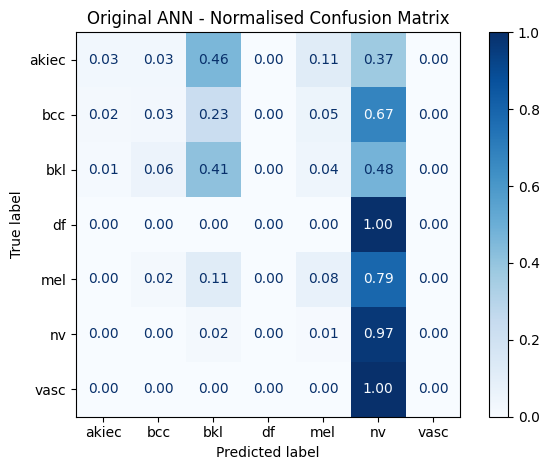

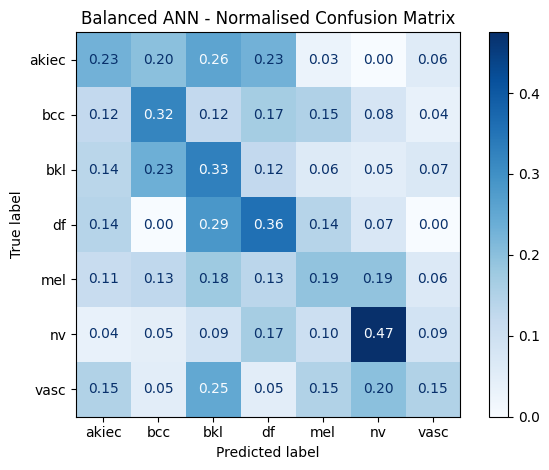

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

classes = sorted(y_val.unique())

# Original ANN confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    ann_pred,
    labels=classes,
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)

plt.title("Original ANN - Normalised Confusion Matrix")
plt.tight_layout()
plt.savefig("ANN_confusion_matrix.png", dpi=300)
plt.show()

# Balanced ANN confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    balanced_pred,
    labels=classes,
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)

plt.title("Balanced ANN - Normalised Confusion Matrix")
plt.tight_layout()
plt.savefig("Balanced_ANN_confusion_matrix.png", dpi=300)
plt.show()


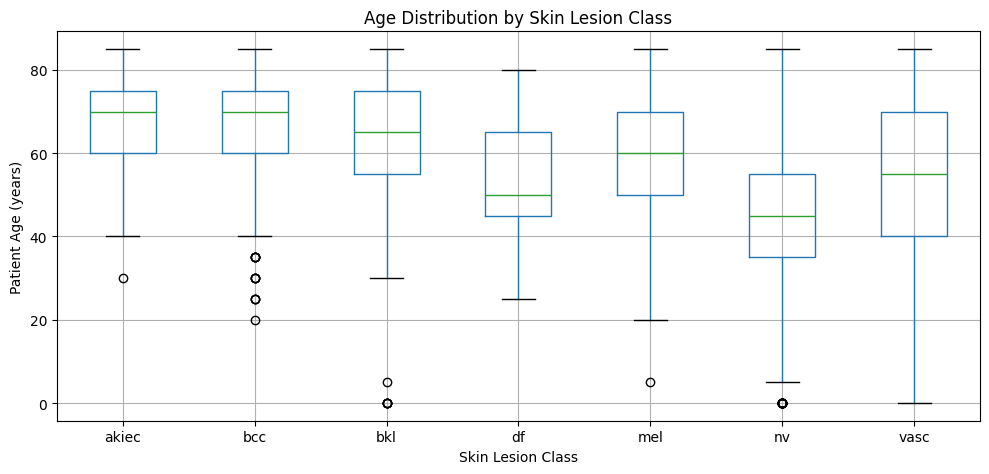

In [ ]:

import matplotlib.pyplot as plt

# Compare ages across the seven lesion classes
df.boxplot(
    column="age",
    by="dx",
    figsize=(10, 5)
)

plt.title("Age Distribution by Skin Lesion Class")
plt.suptitle("")
plt.xlabel("Skin Lesion Class")
plt.ylabel("Patient Age (years)")
plt.tight_layout()

plt.savefig("HAM10000_age_distribution.png", dpi=300)
plt.show()


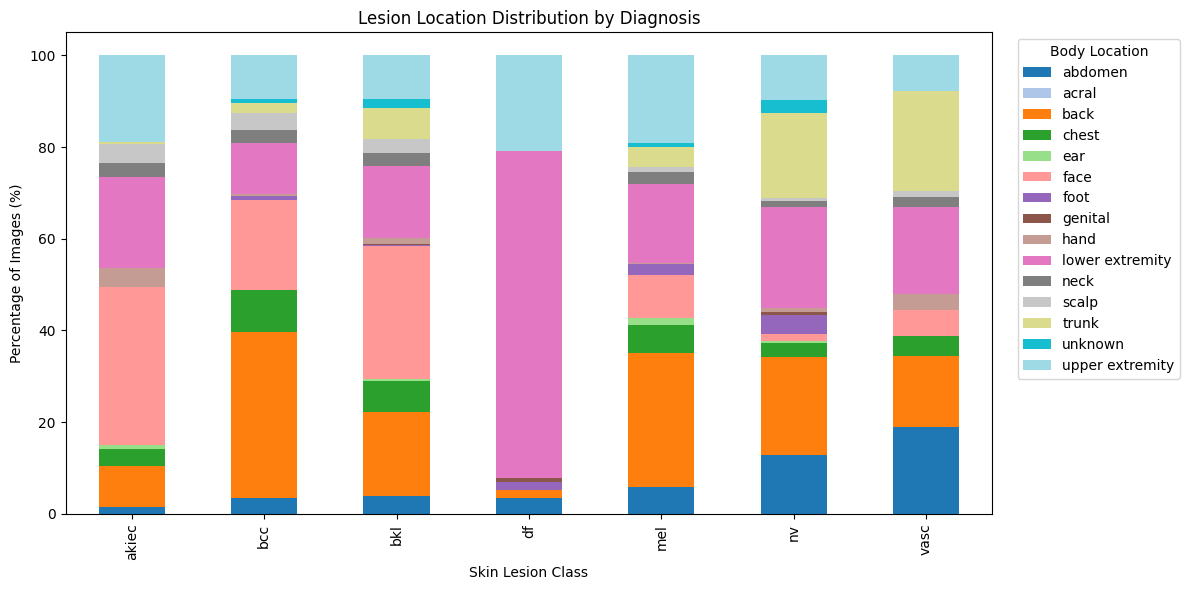

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Count lesions by body location and diagnosis
location_counts = pd.crosstab(
    df["localization"],
    df["dx"]
)

# Convert counts to percentages within each diagnosis
location_percent = (
    location_counts.div(location_counts.sum(axis=0), axis=1) * 100
)

# Plot
location_percent.T.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20"
)

plt.title("Lesion Location Distribution by Diagnosis")
plt.xlabel("Skin Lesion Class")
plt.ylabel("Percentage of Images (%)")
plt.legend(
    title="Body Location",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()

plt.savefig("HAM10000_location_distribution.png", dpi=300)
plt.show()


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import LabelEncoder
from sklearn.base import clone

# Fit preprocessing using training data only
cluster_preprocessor = clone(preprocessor)

X_cluster = cluster_preprocessor.fit_transform(X_train)

# K-Means clustering into 7 groups
kmeans = KMeans(
    n_clusters=7,
    random_state=123,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster)

# Compare clusters with true diagnoses
encoder = LabelEncoder()
true_labels = encoder.fit_transform(y_train)

ari = adjusted_rand_score(true_labels, cluster_labels)

print("K-Means Clustering Results")
print("--------------------------")
print("Adjusted Rand Index:", round(ari, 4))
print("Number of clusters:", len(set(cluster_labels)))


K-Means Clustering Results
--------------------------
Adjusted Rand Index: 0.0249
Number of clusters: 7


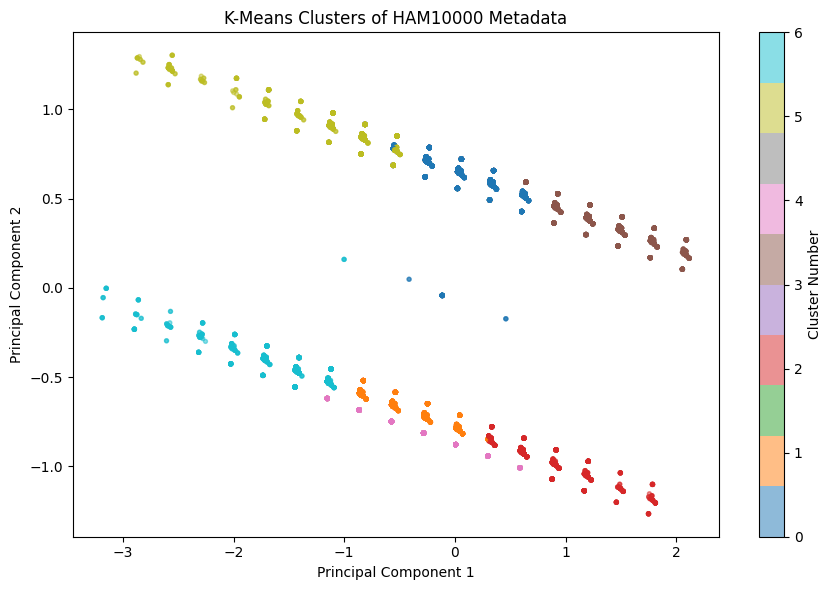

Variance explained by PCA: 63.58 %


In [ ]:

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Convert processed features to a dense array if necessary
X_dense = (
    X_cluster.toarray()
    if hasattr(X_cluster, "toarray")
    else X_cluster
)

# Reduce features to 2 dimensions
pca = PCA(n_components=2, random_state=123)
X_pca = pca.fit_transform(X_dense)

# Plot the clusters
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="tab10",
    s=8,
    alpha=0.5
)

plt.title("K-Means Clusters of HAM10000 Metadata")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster Number")
plt.tight_layout()

plt.savefig("HAM10000_kmeans_clusters.png", dpi=300)
plt.show()

print(
    "Variance explained by PCA:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


In [ ]:

from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

# Create a GMM with seven clusters
gmm = GaussianMixture(
    n_components=7,
    covariance_type="diag",
    reg_covar=1e-4,
    random_state=123
)

# Train the GMM on preprocessed training metadata
gmm_labels = gmm.fit_predict(X_dense)

# Compare clusters with actual lesion classes
gmm_ari = adjusted_rand_score(
    true_labels,
    gmm_labels
)

# Compare both clustering algorithms
print("Clustering Comparison")
print("----------------------")
print("K-Means ARI:", round(ari, 4))
print("GMM ARI:", round(gmm_ari, 4))
print("GMM number of clusters:", len(set(gmm_labels)))


Clustering Comparison
----------------------
K-Means ARI: 0.0249
GMM ARI: 0.0737
GMM number of clusters: 7


In [ ]:

from sklearn.metrics import silhouette_score

# Use the same sample for both models
sample_size = min(2000, len(X_dense))

# Calculate silhouette scores
kmeans_silhouette = silhouette_score(
    X_dense,
    cluster_labels,
    sample_size=sample_size,
    random_state=123
)

gmm_silhouette = silhouette_score(
    X_dense,
    gmm_labels,
    sample_size=sample_size,
    random_state=123
)

print("Clustering Evaluation")
print("---------------------")
print("K-Means ARI:", round(ari, 4))
print("K-Means Silhouette:", round(kmeans_silhouette, 4))

print("\nGMM ARI:", round(gmm_ari, 4))
print("GMM Silhouette:", round(gmm_silhouette, 4))


Clustering Evaluation
---------------------
K-Means ARI: 0.0249
K-Means Silhouette: 0.2193

GMM ARI: 0.0737
GMM Silhouette: 0.1776


,Neighbours (k),Validation Macro F1
0,3,0.2222
1,5,0.2317
2,7,0.2184
3,11,0.2352
4,15,0.2162
5,21,0.2134
6,31,0.2060
7,51,0.2109


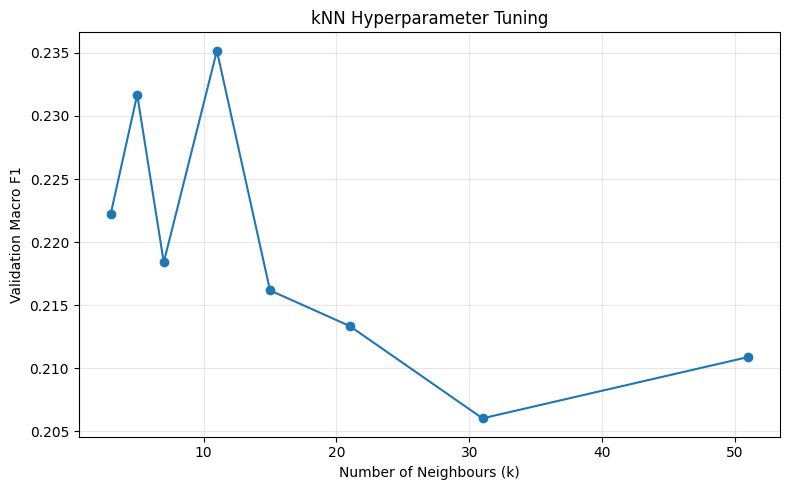

Best k: 11
Best validation Macro F1: 0.2352


In [ ]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import f1_score
import pandas as pd
import matplotlib.pyplot as plt

# Try different numbers of neighbours
k_values = [3, 5, 7, 11, 15, 21, 31, 51]
scores = []

for k in k_values:

    model = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", KNeighborsClassifier(
            n_neighbors=k,
            weights="distance"
        ))
    ])

    # Train using the training set only
    model.fit(X_train, y_train)

    # Evaluate using validation data
    predictions = model.predict(X_val)

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro"
    )

    scores.append(macro_f1)

# Display results
knn_tuning = pd.DataFrame({
    "Neighbours (k)": k_values,
    "Validation Macro F1": scores
})

display(knn_tuning.round(4))

# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(k_values, scores, marker="o")

plt.xlabel("Number of Neighbours (k)")
plt.ylabel("Validation Macro F1")
plt.title("kNN Hyperparameter Tuning")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("HAM10000_knn_tuning.png", dpi=300)
plt.show()

# Identify the best k
best_k = k_values[scores.index(max(scores))]

print("Best k:", best_k)
print("Best validation Macro F1:", round(max(scores), 4))


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import f1_score
import pandas as pd
import matplotlib.pyplot as plt

# Hyperparameter combinations
depth_values = [5, 10, 20, None]
leaf_values = [1, 5, 10]

rf_results = []

for depth in depth_values:
    for leaf in leaf_values:

        model = Pipeline([
            ("preprocessing", clone(preprocessor)),
            ("classifier", RandomForestClassifier(
                n_estimators=200,
                max_depth=depth,
                min_samples_leaf=leaf,
                class_weight="balanced_subsample",
                random_state=123,
                n_jobs=-1
            ))
        ])

        model.fit(X_train, y_train)
        predictions = model.predict(X_val)

        macro_f1 = f1_score(
            y_val,
            predictions,
            average="macro"
        )

        rf_results.append({
            "Max Depth": str(depth),
            "Min Leaf": leaf,
            "Macro F1": macro_f1
        })

# Display results
rf_tuning = pd.DataFrame(rf_results)

display(
    rf_tuning.sort_values(
        "Macro F1",
        ascending=False
    ).round(4)
)

# Show best settings
best_rf = rf_tuning.sort_values(
    "Macro F1",
    ascending=False
).iloc[0]

print("\nBest Random Forest Settings:")
print(best_rf)


,Max Depth,Min Leaf,Macro F1
5,10,10,0.2281
3,10,1,0.2271
8,20,10,0.2247
11,None,10,0.2247
10,None,5,0.2246
4,10,5,0.2232
7,20,5,0.2217
1,5,5,0.2212
9,None,1,0.2142
6,20,1,0.2139



Best Random Forest Settings:
Max Depth          10
Min Leaf           10
Macro F1     0.228076
Name: 5, dtype: object


,C,Validation Macro F1
0,0.001,0.2021
1,0.010,0.1847
2,0.100,0.1897
3,1.000,0.1872
4,10.000,0.1893
5,100.000,0.1868


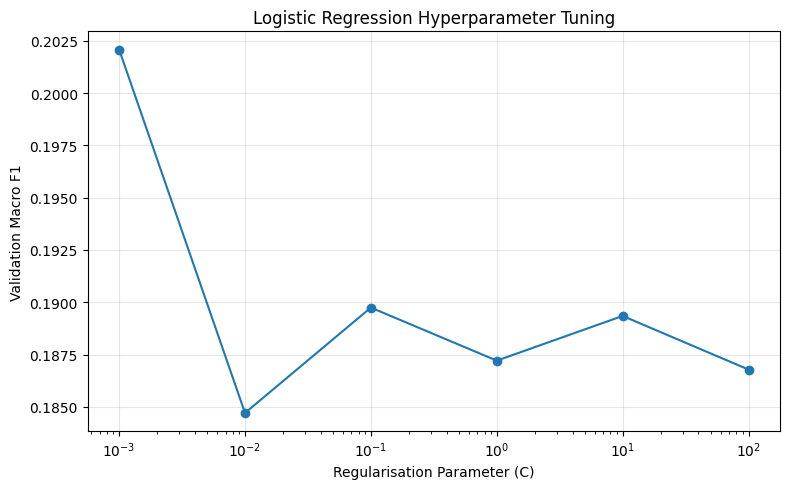

Best C: 0.001
Best Validation Macro F1: 0.2021


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import f1_score
import pandas as pd
import matplotlib.pyplot as plt

# Different regularisation values
c_values = [0.001, 0.01, 0.1, 1, 10, 100]

lr_scores = []

for c in c_values:

    model = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", LogisticRegression(
            C=c,
            max_iter=3000,
            class_weight="balanced",
            random_state=123
        ))
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    score = f1_score(
        y_val,
        predictions,
        average="macro"
    )

    lr_scores.append(score)

# Create results table
lr_tuning = pd.DataFrame({
    "C": c_values,
    "Validation Macro F1": lr_scores
})

display(lr_tuning.round(4))

# Plot tuning results
plt.figure(figsize=(8, 5))
plt.semilogx(c_values, lr_scores, marker="o")
plt.xlabel("Regularisation Parameter (C)")
plt.ylabel("Validation Macro F1")
plt.title("Logistic Regression Hyperparameter Tuning")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("HAM10000_logistic_tuning.png", dpi=300)
plt.show()

# Best parameter
best_c = c_values[lr_scores.index(max(lr_scores))]

print("Best C:", best_c)
print("Best Validation Macro F1:", round(max(lr_scores), 4))


In [ ]:

import pandas as pd

# Save the best validation results from our tuning experiments
tuned_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "kNN"
    ],
    "Best Parameters": [
        "C=0.001",
        "max_depth=10, min_samples_leaf=10",
        "n_neighbors=11"
    ],
    "Baseline Macro F1": [
        0.1872,
        0.2246,
        0.2317
    ],
    "Tuned Macro F1": [
        max(lr_scores),
        rf_tuning["Macro F1"].max(),
        max(scores)
    ]
})

tuned_results["Improvement"] = (
    tuned_results["Tuned Macro F1"]
    - tuned_results["Baseline Macro F1"]
)

display(tuned_results.round(4))

tuned_results.to_csv(
    "HAM10000_tuned_model_results.csv",
    index=False
)


,Model,Best Parameters,Baseline Macro F1,Tuned Macro F1,Improvement
0,Logistic Regression,C=0.001,0.1872,0.2021,0.0149
1,Random Forest,"max_depth=10, min_samples_leaf=10",0.2246,0.2281,0.0035
2,kNN,n_neighbors=11,0.2317,0.2352,0.0035


In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Create Decision Tree
dt_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=123
    ))
])

# Train on training data
dt_model.fit(X_train, y_train)

# Predict on validation data
dt_pred = dt_model.predict(X_val)

# Evaluate
print("Decision Tree Results")
print("---------------------")

print("Accuracy:", round(accuracy_score(y_val, dt_pred), 4))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_val, dt_pred), 4
))
print("Macro F1:", round(
    f1_score(y_val, dt_pred, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val, dt_pred, zero_division=0
))


Decision Tree Results
---------------------
Accuracy: 0.3792
Balanced Accuracy: 0.3033
Macro F1: 0.2114

Classification Report:
              precision    recall  f1-score   support

       akiec       0.09      0.23      0.12        35
         bcc       0.24      0.39      0.30       113
         bkl       0.16      0.09      0.12       162
          df       0.03      0.57      0.05        14
         mel       0.26      0.23      0.25       141
          nv       0.89      0.46      0.60       939
        vasc       0.02      0.15      0.04        20

    accuracy                           0.38      1424
   macro avg       0.24      0.30      0.21      1424
weighted avg       0.65      0.38      0.46      1424



In [ ]:

from google.colab import drive
import os

# Connect Google Drive
drive.mount('/content/drive')

# Location of the HAM10000 image ZIP files
zip_folder = "/content/drive/MyDrive/DMML Project/HAM10000 Images"

# Check that both ZIP files are available
print(os.listdir(zip_folder))


Mounted at /content/drive
['HAM10000_images_part_1.zip', 'HAM10000_images_part_2.zip']


In [ ]:

import zipfile
import os

# Folder to store extracted images in Colab
image_folder = "/content/HAM10000_images"
os.makedirs(image_folder, exist_ok=True)

# Extract both ZIP files
for part in [1, 2]:
    zip_path = os.path.join(
        zip_folder,
        f"HAM10000_images_part_{part}.zip"
    )

    print(f"Extracting part {part}...")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(image_folder)

    print(f"Part {part} extracted!")

print("\nExtraction complete!")

# Find images, including any nested folders
image_paths = []

for root, dirs, files in os.walk(image_folder):
    for filename in files:
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(root, filename))

print("Total image files found:", len(image_paths))


Extracting part 1...
Part 1 extracted!
Extracting part 2...
Part 2 extracted!

Extraction complete!
Total image files found: 10015


In [ ]:

import os
from collections import Counter

# Match image IDs to file paths
image_dict = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_paths
}

# Compare against the metadata
metadata_ids = set(df["image_id"])
file_ids = set(image_dict.keys())

missing_images = metadata_ids - file_ids
extra_images = file_ids - metadata_ids

print("Images in metadata:", len(metadata_ids))
print("Unique image files:", len(file_ids))
print("Missing images:", len(missing_images))
print("Extra images:", len(extra_images))

# Check for duplicate filenames
file_names = [
    os.path.splitext(os.path.basename(path))[0]
    for path in image_paths
]

duplicates = [
    name for name, count in Counter(file_names).items()
    if count > 1
]

print("Duplicate image IDs:", len(duplicates))

# Confirm that the split covers every image
assert set(df["split"]) == {"train", "val", "test"}
assert df["image_id"].is_unique

print("\nSplit distribution:")
print(df["split"].value_counts())

assert len(missing_images) == 0
assert len(extra_images) == 0
assert len(duplicates) == 0

print("\nAll image checks passed!")


Images in metadata: 10015
Unique image files: 10015
Missing images: 0
Extra images: 0
Duplicate image IDs: 0

Split distribution:
split
train    7169
val      1424
test     1422
Name: count, dtype: int64

All image checks passed!


In [ ]:

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Resize images and convert them to tensors
basic_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# Convert diagnosis labels into numbers
classes = sorted(df["dx"].unique())
class_to_idx = {
    name: i for i, name in enumerate(classes)
}

print("Class mapping:", class_to_idx)

# Custom dataset for HAM10000 images
class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, image_dict, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dict = image_dict
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = self.image_dict[row["image_id"]]
        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = class_to_idx[row["dx"]]

        return image, label


# Create training and validation datasets
train_dataset = HAM10000Dataset(
    df[df["split"] == "train"],
    image_dict,
    basic_transform
)

val_dataset = HAM10000Dataset(
    df[df["split"] == "val"],
    image_dict,
    basic_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

# Check one image
sample_image, sample_label = train_dataset[0]

print("Image shape:", sample_image.shape)
print("Label:", classes[sample_label])


Class mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
Training images: 7169
Validation images: 1424
Image shape: torch.Size([3, 224, 224])
Label: bkl


In [ ]:

import torch
from torch.utils.data import DataLoader

# Load training images in batches
stats_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# Accumulate per-channel image statistics
channel_sum = torch.zeros(3)
channel_squared_sum = torch.zeros(3)
total_pixels = 0

for images, labels in stats_loader:
    channel_sum += images.sum(dim=(0, 2, 3))
    channel_squared_sum += (images ** 2).sum(dim=(0, 2, 3))
    total_pixels += images.shape[0] * images.shape[2] * images.shape[3]

# Calculate mean and standard deviation
mean = channel_sum / total_pixels

std = torch.sqrt(
    channel_squared_sum / total_pixels - mean ** 2
)

print("Training image mean:", mean.tolist())
print("Training image std:", std.tolist())


Training image mean: [0.7626866102218628, 0.5461599826812744, 0.5705549120903015]
Training image std: [0.1411413699388504, 0.1523573398590088, 0.16947369277477264]


In [ ]:

from torchvision import transforms
from torch.utils.data import DataLoader

# Normalisation calculated from training images only
image_mean = mean.tolist()
image_std = std.tolist()

# Training: apply augmentation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

# Validation: no random augmentation
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

# Create datasets with their respective transforms
cnn_train_dataset = HAM10000Dataset(
    df[df["split"] == "train"],
    image_dict,
    train_transform
)

cnn_val_dataset = HAM10000Dataset(
    df[df["split"] == "val"],
    image_dict,
    val_transform
)

# Create DataLoaders
train_loader = DataLoader(
    cnn_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    cnn_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# Check one batch
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])
Training batches: 225
Validation batches: 45


In [ ]:

import torch
import torch.nn as nn

# Use GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

# Define our small CNN
class SmallCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

# Create the CNN
cnn_model = SmallCNN(num_classes=7).to(device)

# Display the model
print(cnn_model)

# Count trainable parameters
total_params = sum(
    p.numel() for p in cnn_model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", total_params)


Using device: cuda
SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=64, out_features=7, bias=True)
  )
)

Trainable parameters: 24039


In [ ]:

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# Count images per class in the training set
train_counts = (
    df[df["split"] == "train"]["dx"]
    .value_counts()
    .reindex(classes)
)

print("Training images per class:")
print(train_counts)

# Calculate balanced class weights
counts = train_counts.values.astype(float)

weights = len(cnn_train_dataset) / (
    len(classes) * counts
)

# Convert weights to a PyTorch tensor
class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(device)

print("\nClass weights:")
for name, weight in zip(classes, weights):
    print(name, round(weight, 4))

# Loss function with class weighting
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Adam optimiser
optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

print("\nLoss function and optimiser ready!")


NameError: name 'df' is not defined

In [ ]:

import pandas as pd

# Load the original metadata
df = pd.read_csv("HAM10000_metadata.csv")

# Load our saved train/validation/test assignments
splits = pd.read_csv("HAM10000_splits.csv")

# Add the saved split assignments to the metadata
df = df.merge(
    splits[["image_id", "split"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

# Check everything is correct
print(df["split"].value_counts())
print("Missing split assignments:", df["split"].isna().sum())


FileNotFoundError: [Errno 2] No such file or directory: 'HAM10000_metadata.csv'

In [ ]:

from google.colab import files

uploaded = files.upload()



Saving HAM10000_splits.csv to HAM10000_splits.csv


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving HAM10000_metadata.csv to HAM10000_metadata.csv


In [ ]:

import pandas as pd

df = pd.read_csv("HAM10000_metadata.csv")
splits = pd.read_csv("HAM10000_splits.csv")

df = df.merge(
    splits[["image_id", "split"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

print(df["split"].value_counts())
print("Missing assignments:", df["split"].isna().sum())


split
train    7169
val      1424
test     1422
Name: count, dtype: int64
Missing assignments: 0


In [ ]:

import os

image_folder = "/content/HAM10000_images"

if os.path.exists(image_folder):
    image_count = sum(
        1
        for root, dirs, files in os.walk(image_folder)
        for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    )
    print("Images found:", image_count)
else:
    print("Image folder missing - extraction needed")


Image folder missing - extraction needed


In [ ]:

from google.colab import drive
import os
import zipfile

# Reconnect Google Drive
drive.mount("/content/drive")

# Google Drive folder containing both ZIP files
zip_folder = "/content/drive/MyDrive/DMML Project/HAM10000 Images"

# Extract into Colab's temporary storage
image_folder = "/content/HAM10000_images"
os.makedirs(image_folder, exist_ok=True)

for part in [1, 2]:
    zip_path = os.path.join(
        zip_folder,
        f"HAM10000_images_part_{part}.zip"
    )

    print(f"Extracting part {part}...")

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(image_folder)

# Locate all extracted images
image_paths = [
    os.path.join(root, filename)
    for root, dirs, filenames in os.walk(image_folder)
    for filename in filenames
    if filename.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Match image IDs to paths
image_dict = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_paths
}

print("\nTotal images:", len(image_paths))
print("Unique image IDs:", len(image_dict))

# Verify every metadata image is available
assert len(image_paths) == 10015
assert len(image_dict) == 10015
assert set(df["image_id"]) == set(image_dict)

print("All image checks passed!")


Mounted at /content/drive
Extracting part 1...


OSError: [Errno 107] Transport endpoint is not connected

In [ ]:

from google.colab import drive

# Disconnect the broken Google Drive mount
drive.flush_and_unmount()

# Reconnect Google Drive
drive.mount("/content/drive", force_remount=True)

print("Google Drive reconnected!")


Mounted at /content/drive
Google Drive reconnected!


In [ ]:

import os

zip_folder = "/content/drive/MyDrive/DMML Project/HAM10000 Images"

for part in [1, 2]:
    path = os.path.join(
        zip_folder,
        f"HAM10000_images_part_{part}.zip"
    )

    print(f"Part {part} exists:", os.path.isfile(path))


Part 1 exists: True
Part 2 exists: True


In [ ]:

import os
import shutil
import zipfile

zip_folder = "/content/drive/MyDrive/DMML Project/HAM10000 Images"
local_folder = "/content/HAM10000_zips"
image_folder = "/content/HAM10000_images"

os.makedirs(local_folder, exist_ok=True)
os.makedirs(image_folder, exist_ok=True)

# Copy both ZIP files from Drive to Colab
for part in [1, 2]:
    filename = f"HAM10000_images_part_{part}.zip"

    source = os.path.join(zip_folder, filename)
    destination = os.path.join(local_folder, filename)

    print(f"Copying part {part}...")
    shutil.copy2(source, destination)

    print(f"Extracting part {part}...")
    with zipfile.ZipFile(destination, "r") as z:
        bad_file = z.testzip()
        if bad_file is not None:
            raise ValueError(f"Corrupt ZIP entry: {bad_file}")
        z.extractall(image_folder)

    print(f"Part {part} complete!")

# Find all images
image_paths = [
    os.path.join(root, filename)
    for root, dirs, filenames in os.walk(image_folder)
    for filename in filenames
    if filename.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_dict = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_paths
}

# Verify the images
print("\nTotal images:", len(image_paths))
print("Unique image IDs:", len(image_dict))

assert len(image_paths) == 10015
assert len(image_dict) == 10015
assert set(df["image_id"]) == set(image_dict.keys())

print("All image checks passed!")


Copying part 1...
Extracting part 1...
Part 1 complete!
Copying part 2...
Extracting part 2...
Part 2 complete!

Total images: 10015
Unique image IDs: 10015
All image checks passed!


In [ ]:

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Normalisation values from our original training set
image_mean = [0.76268661, 0.54615998, 0.57055491]
image_std = [0.14114137, 0.15235734, 0.16947369]

# Seven lesion classes
classes = sorted(df["dx"].unique())
class_to_idx = {name: i for i, name in enumerate(classes)}

# Dataset class
class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, image_dict, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dict = image_dict
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = Image.open(
            self.image_dict[row["image_id"]]
        ).convert("RGB")

        image = self.transform(image)
        label = class_to_idx[row["dx"]]

        return image, label

# Training augmentation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

# Validation: no augmentation
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

# Create datasets
cnn_train_dataset = HAM10000Dataset(
    df[df["split"] == "train"],
    image_dict,
    train_transform
)

cnn_val_dataset = HAM10000Dataset(
    df[df["split"] == "val"],
    image_dict,
    val_transform
)

# Create DataLoaders
train_loader = DataLoader(
    cnn_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    cnn_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("Training images:", len(cnn_train_dataset))
print("Validation images:", len(cnn_val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("GPU available:", torch.cuda.is_available())


Training images: 7169
Validation images: 1424
Training batches: 225
Validation batches: 45
GPU available: True


In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Small CNN architecture
class SmallCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

# Create model
torch.manual_seed(123)
cnn_model = SmallCNN(num_classes=7).to(device)

# Count training images for each lesion class
train_counts = (
    df[df["split"] == "train"]["dx"]
    .value_counts()
    .reindex(classes)
)

# Calculate weights from training data only
counts = train_counts.values.astype(float)

weights = len(cnn_train_dataset) / (len(classes) * counts)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

# Weighted loss to address class imbalance
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Optimiser
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

print("Using device:", device)
print("\nTraining class counts:")
print(train_counts)

print("\nClass weights:")
for name, weight in zip(classes, weights):
    print(name, round(weight, 4))

print("\nCNN and optimiser ready!")


Using device: cuda

Training class counts:
dx
akiec     236
bcc       349
bkl       794
df         86
mel       816
nv       4788
vasc      100
Name: count, dtype: int64

Class weights:
akiec 4.3396
bcc 2.9345
bkl 1.2899
df 11.9086
mel 1.2551
nv 0.2139
vasc 10.2414

CNN and optimiser ready!


In [ ]:

import torch
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score

# Training settings
epochs = 10
best_f1 = -1

history = []

for epoch in range(epochs):

    # TRAINING
    cnn_model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

    # VALIDATION
    cnn_model.eval()
    val_loss = 0
    val_preds = []
    val_true = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            val_preds.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )
            val_true.extend(labels.cpu().numpy())

    # Calculate metrics
    avg_train_loss = train_loss / train_total
    avg_val_loss = val_loss / len(cnn_val_dataset)

    train_accuracy = train_correct / train_total
    val_accuracy = accuracy_score(val_true, val_preds)
    val_f1 = f1_score(
        val_true,
        val_preds,
        average="macro",
        zero_division=0
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_f1
    })

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

    # Save the best model
    if val_f1 > best_f1:
        best_f1 = val_f1

        torch.save(
            cnn_model.state_dict(),
            "/content/best_small_cnn.pth"
        )

        print("Best model saved!")

# Save training history
history_df = pd.DataFrame(history)
history_df.to_csv(
    "/content/small_cnn_training_history.csv",
    index=False
)

print("\nBest Validation Macro F1:", round(best_f1, 4))


Epoch 1/10 | Train Loss: 1.8422 | Val Loss: 1.3847 | Val Accuracy: 0.5169 | Val Macro F1: 0.2387
Best model saved!
Epoch 2/10 | Train Loss: 1.7725 | Val Loss: 1.2711 | Val Accuracy: 0.5260 | Val Macro F1: 0.2556
Best model saved!
Epoch 3/10 | Train Loss: 1.6917 | Val Loss: 1.2889 | Val Accuracy: 0.5112 | Val Macro F1: 0.3135
Best model saved!
Epoch 4/10 | Train Loss: 1.6392 | Val Loss: 1.2829 | Val Accuracy: 0.5197 | Val Macro F1: 0.2904
Epoch 5/10 | Train Loss: 1.6223 | Val Loss: 1.3973 | Val Accuracy: 0.4923 | Val Macro F1: 0.2905
Epoch 6/10 | Train Loss: 1.5589 | Val Loss: 1.2801 | Val Accuracy: 0.5176 | Val Macro F1: 0.3083
Epoch 7/10 | Train Loss: 1.5465 | Val Loss: 1.1450 | Val Accuracy: 0.5576 | Val Macro F1: 0.3375
Best model saved!
Epoch 8/10 | Train Loss: 1.5204 | Val Loss: 1.0737 | Val Accuracy: 0.5871 | Val Macro F1: 0.3372
Epoch 9/10 | Train Loss: 1.4868 | Val Loss: 1.2408 | Val Accuracy: 0.5302 | Val Macro F1: 0.3471
Best model saved!
Epoch 10/10 | Train Loss: 1.4952 | Va

In [ ]:

import os
import shutil

# Folder for saved CNN experiments
save_folder = "/content/drive/MyDrive/DMML Project/CNN Results"

os.makedirs(save_folder, exist_ok=True)

# Copy best CNN checkpoint
shutil.copy2(
    "/content/best_small_cnn.pth",
    os.path.join(save_folder, "best_small_cnn.pth")
)

# Copy training history
shutil.copy2(
    "/content/small_cnn_training_history.csv",
    os.path.join(save_folder, "small_cnn_training_history.csv")
)

print("CNN checkpoint and training history saved to Google Drive!")

print("\nSaved files:")
print(os.listdir(save_folder))


FileNotFoundError: [Errno 2] No such file or directory: '/content/best_small_cnn.pth'

In [ ]:
from google.colab import drive
import os

drive.mount("/content/drive")

save_folder = "/content/drive/MyDrive/DMML Project/CNN Results"

if os.path.exists(save_folder):
    print("Saved files:", os.listdir(save_folder))
else:
    print("No CNN Results folder found")

Mounted at /content/drive
Saved files: ['best_small_cnn.pth', 'small_cnn_training_history.csv']


In [ ]:

import os

print("Metadata loaded:", "df" in globals())
print("CNN model loaded:", "cnn_model" in globals())
print("Training DataLoader loaded:", "train_loader" in globals())

print("Images extracted:",
      os.path.exists("/content/HAM10000_images"))

print("GPU available:",
      __import__("torch").cuda.is_available())


Metadata loaded: False
CNN model loaded: False
Training DataLoader loaded: False
Images extracted: False
GPU available: True


In [ ]:

import os
import pandas as pd
from google.colab import files

required_files = [
    "HAM10000_metadata.csv",
    "HAM10000_splits.csv"
]

# Upload only missing CSV files
missing_files = [
    name for name in required_files
    if not os.path.exists(f"/content/{name}")
]

if missing_files:
    print("Please upload:", missing_files)
    files.upload()

# Load the original metadata and saved split
df = pd.read_csv("/content/HAM10000_metadata.csv")
splits = pd.read_csv("/content/HAM10000_splits.csv")

# Reattach the original train/val/test assignments
df = df.merge(
    splits[["image_id", "split"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

# Verify the dataset
assert len(df) == 10015
assert df["split"].notna().all()
assert df.groupby("lesion_id")["split"].nunique().max() == 1

print("\nDataset restored successfully!")
print(df["split"].value_counts())
print("Unique lesions:", df["lesion_id"].nunique())


Please upload: ['HAM10000_splits.csv']


Saving HAM10000_splits.csv to HAM10000_splits.csv

Dataset restored successfully!
split
train    7169
val      1424
test     1422
Name: count, dtype: int64
Unique lesions: 7470


In [ ]:

import os
import shutil
import zipfile

zip_folder = "/content/drive/MyDrive/DMML Project/HAM10000 Images"
local_folder = "/content/HAM10000_zips"
image_folder = "/content/HAM10000_images"

os.makedirs(local_folder, exist_ok=True)
os.makedirs(image_folder, exist_ok=True)

for part in [1, 2]:
    filename = f"HAM10000_images_part_{part}.zip"

    source = os.path.join(zip_folder, filename)
    destination = os.path.join(local_folder, filename)

    # Copy from Drive to Colab storage
    print(f"Copying part {part}...")
    shutil.copy2(source, destination)

    # Extract locally
    print(f"Extracting part {part}...")
    with zipfile.ZipFile(destination, "r") as z:
        z.extractall(image_folder)

    print(f"Part {part} complete!")

# Find images
image_paths = [
    os.path.join(root, filename)
    for root, dirs, filenames in os.walk(image_folder)
    for filename in filenames
    if filename.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Link image IDs to image paths
image_dict = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_paths
}

# Verify all images
print("\nTotal images:", len(image_paths))
print("Unique image IDs:", len(image_dict))

assert len(image_paths) == 10015
assert len(image_dict) == 10015
assert set(df["image_id"]) == set(image_dict)

print("\nAll image checks passed!")


Copying part 1...
Extracting part 1...
Part 1 complete!
Copying part 2...
Extracting part 2...
Part 2 complete!

Total images: 10015
Unique image IDs: 10015

All image checks passed!


In [ ]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Reproducibility
random.seed(123)
np.random.seed(123)
torch.manual_seed(123)
torch.cuda.manual_seed_all(123)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Normalisation values calculated from our training set
image_mean = [0.76268661, 0.54615998, 0.57055491]
image_std = [0.14114137, 0.15235734, 0.16947369]

classes = sorted(df["dx"].unique())
class_to_idx = {name: i for i, name in enumerate(classes)}

class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, image_dict, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dict = image_dict
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = Image.open(
            self.image_dict[row["image_id"]]
        ).convert("RGB")

        image = self.transform(image)
        label = class_to_idx[row["dx"]]
        return image, label

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

train_dataset = HAM10000Dataset(
    df[df["split"] == "train"], image_dict, train_transform
)
val_dataset = HAM10000Dataset(
    df[df["split"] == "val"], image_dict, val_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=2
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=2
)

# Same small CNN architecture as before
class SmallCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

cnn_model = SmallCNN(num_classes=7).to(device)

# Class weights from training split only
train_counts = (
    df[df["split"] == "train"]["dx"]
    .value_counts().reindex(classes)
)

weights = len(train_dataset) / (len(classes) * train_counts.values)

class_weights = torch.tensor(
    weights, dtype=torch.float32, device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

# Permanent location for CNN results
save_folder = "/content/drive/MyDrive/DMML Project/CNN Results"
os.makedirs(save_folder, exist_ok=True)

print("Device:", device)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Model parameters:", sum(p.numel() for p in cnn_model.parameters()))
print("Save folder:", save_folder)
print("Training setup restored!")


Device: cuda
Training images: 7169
Validation images: 1424
Model parameters: 24039
Save folder: /content/drive/MyDrive/DMML Project/CNN Results
Training setup restored!


In [ ]:

import os
import torch
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

epochs = 10
best_f1 = -1
history = []

# Save directly to Google Drive
checkpoint_path = os.path.join(
    save_folder, "best_small_cnn.pth"
)

history_path = os.path.join(
    save_folder, "small_cnn_training_history.csv"
)

for epoch in range(epochs):

    # TRAINING
    cnn_model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

    # VALIDATION
    cnn_model.eval()
    val_loss = 0
    val_preds = []
    val_true = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_preds.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )
            val_true.extend(labels.cpu().numpy())

    # Metrics
    train_loss /= train_total
    val_loss /= len(val_dataset)

    train_accuracy = train_correct / train_total
    val_accuracy = accuracy_score(val_true, val_preds)
    val_f1 = f1_score(
        val_true,
        val_preds,
        average="macro",
        zero_division=0
    )

    # Save training history
    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_f1
    })

    pd.DataFrame(history).to_csv(history_path, index=False)

    # Save best model
    if val_f1 > best_f1:
        best_f1 = val_f1

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": cnn_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_macro_f1": best_f1,
            "classes": classes,
            "image_mean": image_mean,
            "image_std": image_std
        }, checkpoint_path)

        print(f"Epoch {epoch+1}: New best model saved!")

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

print("\nTraining complete!")
print("Best Validation Macro F1:", round(best_f1, 4))
print("Checkpoint saved to:", checkpoint_path)
print("History saved to:", history_path)


Epoch 1: New best model saved!
Epoch 1/10 | Train Loss: 1.8422 | Val Loss: 1.3811 | Val Accuracy: 0.5176 | Val Macro F1: 0.2388
Epoch 2: New best model saved!
Epoch 2/10 | Train Loss: 1.7745 | Val Loss: 1.2800 | Val Accuracy: 0.5281 | Val Macro F1: 0.2588
Epoch 3: New best model saved!
Epoch 3/10 | Train Loss: 1.6860 | Val Loss: 1.2790 | Val Accuracy: 0.5162 | Val Macro F1: 0.3105
Epoch 4/10 | Train Loss: 1.6330 | Val Loss: 1.2749 | Val Accuracy: 0.5281 | Val Macro F1: 0.3045
Epoch 5: New best model saved!
Epoch 5/10 | Train Loss: 1.6034 | Val Loss: 1.3537 | Val Accuracy: 0.5105 | Val Macro F1: 0.3235
Epoch 6/10 | Train Loss: 1.5442 | Val Loss: 1.2607 | Val Accuracy: 0.5239 | Val Macro F1: 0.3225
Epoch 7: New best model saved!
Epoch 7/10 | Train Loss: 1.5279 | Val Loss: 1.1604 | Val Accuracy: 0.5449 | Val Macro F1: 0.3287
Epoch 8: New best model saved!
Epoch 8/10 | Train Loss: 1.4953 | Val Loss: 1.0747 | Val Accuracy: 0.5758 | Val Macro F1: 0.3522
Epoch 9/10 | Train Loss: 1.4766 | Val 

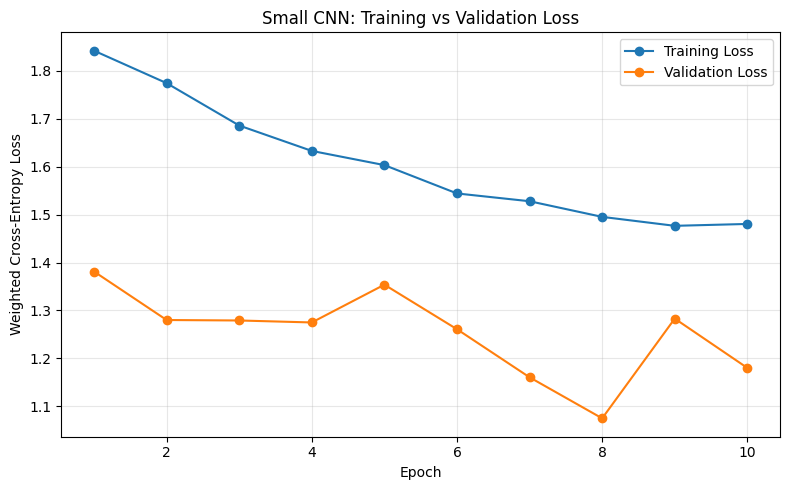

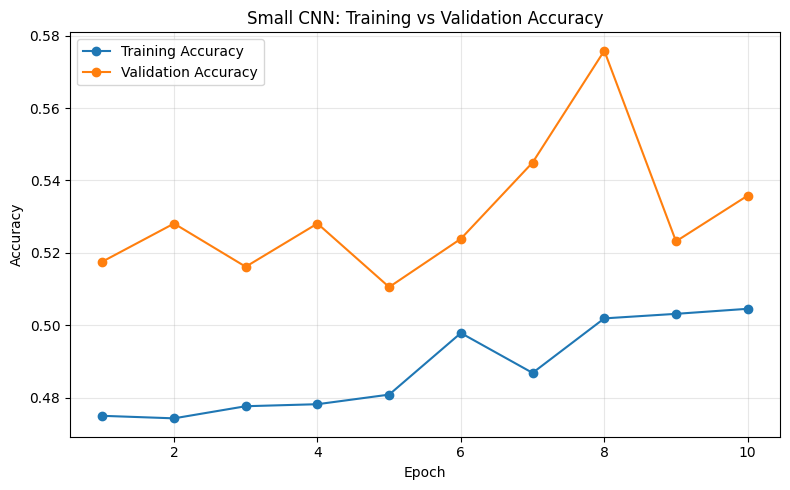

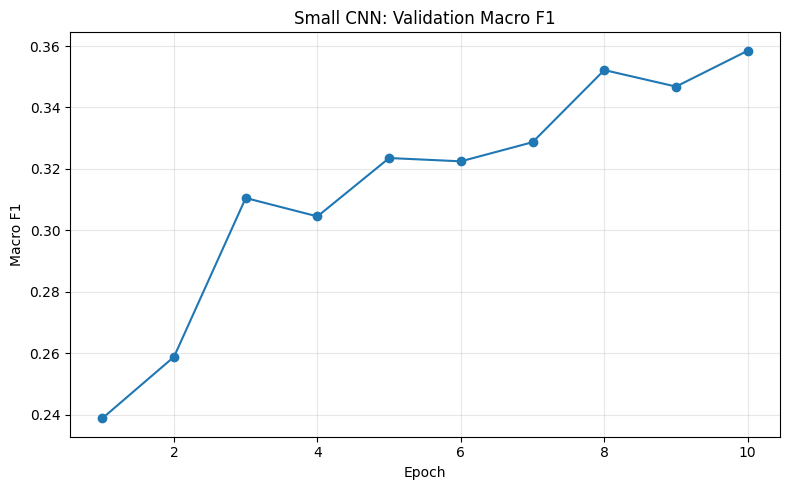

All three graphs saved to Google Drive!


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load saved training history
history_df = pd.read_csv(
    os.path.join(save_folder, "small_cnn_training_history.csv")
)

# Graph 1: Training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Weighted Cross-Entropy Loss")
plt.title("Small CNN: Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(save_folder, "small_cnn_loss.png"),
    dpi=300
)
plt.show()

# Graph 2: Training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)
plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Small CNN: Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(save_folder, "small_cnn_accuracy.png"),
    dpi=300
)
plt.show()

# Graph 3: Validation Macro F1
plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    marker="o"
)
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("Small CNN: Validation Macro F1")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(save_folder, "small_cnn_macro_f1.png"),
    dpi=300
)
plt.show()

print("All three graphs saved to Google Drive!")


Best CNN Validation Results
---------------------------
Accuracy: 0.5358
Balanced Accuracy: 0.456
Macro F1: 0.3585

Classification Report:
              precision    recall  f1-score   support

       akiec       0.15      0.46      0.23        35
         bcc       0.29      0.51      0.37       113
         bkl       0.34      0.43      0.38       162
          df       0.11      0.14      0.12        14
         mel       0.27      0.59      0.37       141
          nv       0.95      0.56      0.70       939
        vasc       0.25      0.50      0.33        20

    accuracy                           0.54      1424
   macro avg       0.34      0.46      0.36      1424
weighted avg       0.73      0.54      0.59      1424



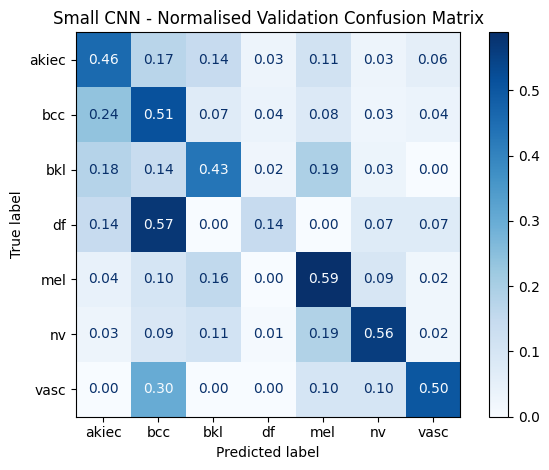

In [ ]:

import os
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)

# Load best CNN checkpoint from Google Drive
checkpoint_path = os.path.join(
    save_folder, "best_small_cnn.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

cnn_model.load_state_dict(
    checkpoint["model_state_dict"]
)

cnn_model.eval()

# Evaluate on validation data only
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = cnn_model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Display results
print("Best CNN Validation Results")
print("---------------------------")
print("Accuracy:", round(
    accuracy_score(all_labels, all_preds), 4
))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(all_labels, all_preds), 4
))
print("Macro F1:", round(
    f1_score(all_labels, all_preds, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

# Normalised confusion matrix
ConfusionMatrixDisplay.from_predictions(
    all_labels,
    all_preds,
    labels=list(range(len(classes))),
    display_labels=classes,
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)

plt.title("Small CNN - Normalised Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(save_folder, "small_cnn_confusion_matrix.png"),
    dpi=300
)

plt.show()


In [ ]:

import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# Load pretrained ResNet18
resnet_model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

# Replace the final classification layer
num_features = resnet_model.fc.in_features

resnet_model.fc = nn.Linear(
    num_features,
    7
)

# Move to GPU
resnet_model = resnet_model.to(device)

print("ResNet18 loaded successfully!")
print("Output classes:", resnet_model.fc.out_features)

total_params = sum(
    p.numel() for p in resnet_model.parameters()
)

print("Total parameters:", total_params)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 55.7MB/s]


ResNet18 loaded successfully!
Output classes: 7
Total parameters: 11180103


In [ ]:

from torchvision import transforms
from torch.utils.data import DataLoader
import torch.nn as nn

# Freeze pretrained layers
for param in resnet_model.parameters():
    param.requires_grad = False

# Unfreeze the final classification layer
for param in resnet_model.fc.parameters():
    param.requires_grad = True

# ImageNet normalisation
resnet_mean = [0.485, 0.456, 0.406]
resnet_std = [0.229, 0.224, 0.225]

# Training augmentation
resnet_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(resnet_mean, resnet_std)
])

# Validation preprocessing (no random augmentation)
resnet_val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(resnet_mean, resnet_std)
])

# Create datasets using our original saved split
resnet_train_dataset = HAM10000Dataset(
    df[df["split"] == "train"],
    image_dict,
    resnet_train_transform
)

resnet_val_dataset = HAM10000Dataset(
    df[df["split"] == "val"],
    image_dict,
    resnet_val_transform
)

# Create DataLoaders
resnet_train_loader = DataLoader(
    resnet_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

resnet_val_loader = DataLoader(
    resnet_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# Count parameters being trained
trainable_params = sum(
    p.numel() for p in resnet_model.parameters()
    if p.requires_grad
)

print("Training images:", len(resnet_train_dataset))
print("Validation images:", len(resnet_val_dataset))
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", sum(
    p.numel() for p in resnet_model.parameters()
    if not p.requires_grad
))


Training images: 7169
Validation images: 1424
Trainable parameters: 3591
Frozen parameters: 11176512


In [ ]:

import os
import torch
import torch.nn as nn
import torch.optim as optim

# Ensure the model is on the GPU
resnet_model = resnet_model.to(device)

# Class-weighted loss from our training split
resnet_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Optimise only the final classification layer
resnet_optimizer = optim.Adam(
    resnet_model.fc.parameters(),
    lr=0.001
)

# Save files to Google Drive
resnet_save_folder = os.path.join(
    save_folder, "ResNet18"
)

os.makedirs(resnet_save_folder, exist_ok=True)

print("Device:", device)
print("Trainable parameters:", sum(
    p.numel() for p in resnet_model.parameters()
    if p.requires_grad
))
print("Save folder:", resnet_save_folder)
print("ResNet18 training configuration ready!")


Device: cuda
Trainable parameters: 3591
Save folder: /content/drive/MyDrive/DMML Project/CNN Results/ResNet18
ResNet18 training configuration ready!


In [ ]:

import os
import torch
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

epochs = 10
best_resnet_f1 = -1
resnet_history = []

resnet_checkpoint_path = os.path.join(
    resnet_save_folder, "best_resnet18.pth"
)

resnet_history_path = os.path.join(
    resnet_save_folder, "resnet18_training_history.csv"
)

for epoch in range(epochs):

    # TRAINING
    # Keep pretrained BatchNorm statistics frozen
    resnet_model.eval()
    resnet_model.fc.train()

    train_loss_sum = 0
    train_correct = 0
    train_total = 0

    for images, labels in resnet_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        resnet_optimizer.zero_grad()

        outputs = resnet_model(images)
        loss = resnet_criterion(outputs, labels)

        loss.backward()
        resnet_optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

    # VALIDATION
    resnet_model.eval()
    val_loss_sum = 0
    val_preds = []
    val_true = []

    with torch.no_grad():
        for images, labels in resnet_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet_model(images)
            loss = resnet_criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_preds.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )
            val_true.extend(labels.cpu().numpy())

    # Calculate metrics
    train_loss = train_loss_sum / train_total
    val_loss = val_loss_sum / len(resnet_val_dataset)

    train_accuracy = train_correct / train_total
    val_accuracy = accuracy_score(val_true, val_preds)
    val_f1 = f1_score(
        val_true,
        val_preds,
        average="macro",
        zero_division=0
    )

    # Record results
    resnet_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_f1
    })

    # Save history after every epoch
    pd.DataFrame(resnet_history).to_csv(
        resnet_history_path,
        index=False
    )

    # Save best checkpoint to Google Drive
    if val_f1 > best_resnet_f1:
        best_resnet_f1 = val_f1

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": resnet_model.state_dict(),
            "optimizer_state_dict": resnet_optimizer.state_dict(),
            "best_val_macro_f1": best_resnet_f1,
            "classes": classes
        }, resnet_checkpoint_path)

        print(f"Epoch {epoch+1}: New best ResNet18 saved!")

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

print("\nResNet18 training complete!")
print("Best Validation Macro F1:", round(best_resnet_f1, 4))
print("Checkpoint:", resnet_checkpoint_path)
print("History:", resnet_history_path)


Epoch 1: New best ResNet18 saved!
Epoch 1/10 | Train Loss: 1.6633 | Val Loss: 1.6122 | Val Accuracy: 0.3982 | Val Macro F1: 0.2831
Epoch 2: New best ResNet18 saved!
Epoch 2/10 | Train Loss: 1.4284 | Val Loss: 1.4648 | Val Accuracy: 0.4649 | Val Macro F1: 0.3525
Epoch 3/10 | Train Loss: 1.3208 | Val Loss: 1.2980 | Val Accuracy: 0.5183 | Val Macro F1: 0.3208
Epoch 4: New best ResNet18 saved!
Epoch 4/10 | Train Loss: 1.2828 | Val Loss: 1.1697 | Val Accuracy: 0.5794 | Val Macro F1: 0.3788
Epoch 5/10 | Train Loss: 1.2295 | Val Loss: 1.2648 | Val Accuracy: 0.5169 | Val Macro F1: 0.3095
Epoch 6/10 | Train Loss: 1.1971 | Val Loss: 1.4066 | Val Accuracy: 0.4698 | Val Macro F1: 0.3248
Epoch 7/10 | Train Loss: 1.1797 | Val Loss: 1.3030 | Val Accuracy: 0.5225 | Val Macro F1: 0.3668
Epoch 8/10 | Train Loss: 1.1544 | Val Loss: 1.3001 | Val Accuracy: 0.5435 | Val Macro F1: 0.3786
Epoch 9/10 | Train Loss: 1.1196 | Val Loss: 1.4129 | Val Accuracy: 0.5133 | Val Macro F1: 0.3606
Epoch 10: New best ResNet

BEST RESNET18 VALIDATION RESULTS
--------------------------------
Accuracy: 0.5857
Balanced Accuracy: 0.5448
Macro F1: 0.4354

Classification Report:
              precision    recall  f1-score   support

       akiec       0.31      0.54      0.39        35
         bcc       0.38      0.68      0.49       113
         bkl       0.31      0.43      0.36       162
          df       0.24      0.36      0.29        14
         mel       0.29      0.54      0.38       141
          nv       0.95      0.61      0.74       939
        vasc       0.29      0.65      0.40        20

    accuracy                           0.59      1424
   macro avg       0.39      0.54      0.44      1424
weighted avg       0.73      0.59      0.63      1424



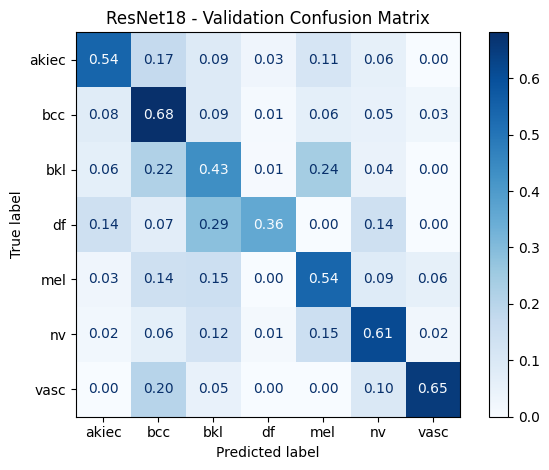

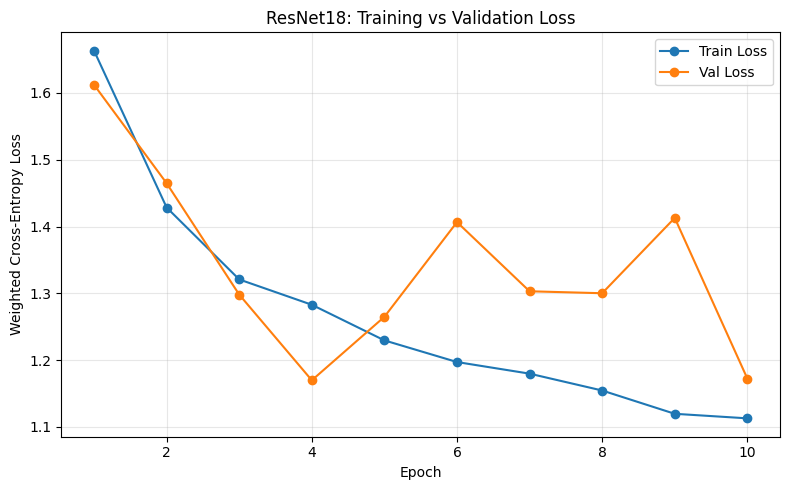

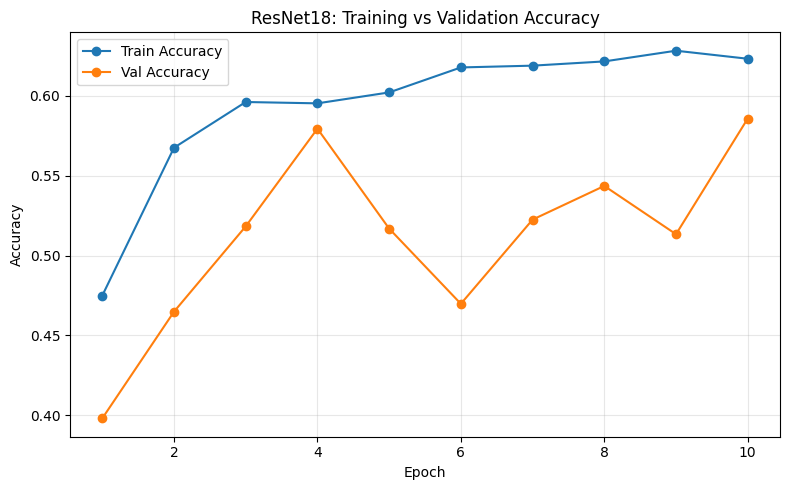

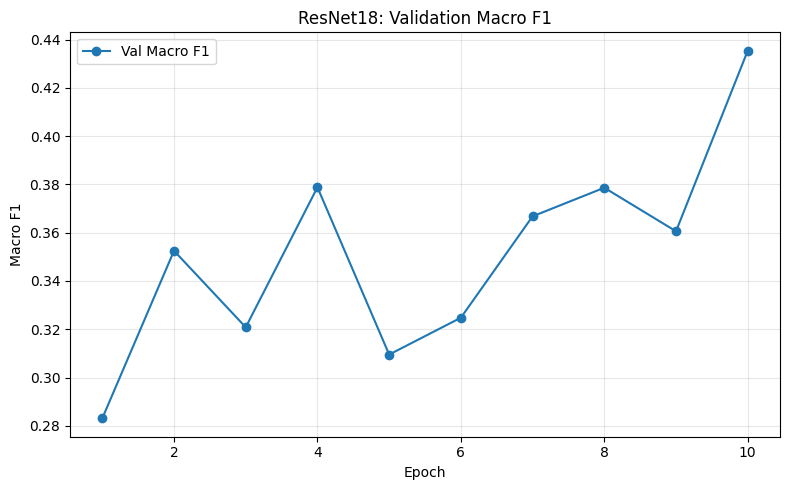

,Model,Validation Macro F1,Validation Accuracy
0,Small CNN,0.3585,0.5358
1,ResNet18 (Frozen Backbone),0.4354,0.5857


All results saved to Google Drive!


In [ ]:

import os
import torch
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Load the best ResNet18 checkpoint
checkpoint = torch.load(
    os.path.join(resnet_save_folder, "best_resnet18.pth"),
    map_location=device,
    weights_only=True
)

resnet_model.load_state_dict(checkpoint["model_state_dict"])
resnet_model.eval()

# 2. Evaluate on validation data only
all_preds = []
all_true = []

with torch.no_grad():
    for images, labels in resnet_val_loader:
        images = images.to(device)
        outputs = resnet_model(images)

        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_true.extend(labels.numpy())

print("BEST RESNET18 VALIDATION RESULTS")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(all_true, all_preds), 4))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(all_true, all_preds), 4
))
print("Macro F1:", round(
    f1_score(all_true, all_preds, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    all_true,
    all_preds,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

# 3. Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    all_true,
    all_preds,
    labels=list(range(len(classes))),
    display_labels=classes,
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)

plt.title("ResNet18 - Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(
    os.path.join(resnet_save_folder, "resnet18_confusion_matrix.png"),
    dpi=300
)
plt.show()

# 4. Training graphs
history = pd.read_csv(
    os.path.join(resnet_save_folder, "resnet18_training_history.csv")
)

for columns, title, filename, ylabel in [
    (
        ["train_loss", "val_loss"],
        "ResNet18: Training vs Validation Loss",
        "resnet18_loss.png",
        "Weighted Cross-Entropy Loss"
    ),
    (
        ["train_accuracy", "val_accuracy"],
        "ResNet18: Training vs Validation Accuracy",
        "resnet18_accuracy.png",
        "Accuracy"
    ),
    (
        ["val_macro_f1"],
        "ResNet18: Validation Macro F1",
        "resnet18_macro_f1.png",
        "Macro F1"
    )
]:
    plt.figure(figsize=(8, 5))

    for column in columns:
        plt.plot(
            history["epoch"],
            history[column],
            marker="o",
            label=column.replace("_", " ").title()
        )

    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(resnet_save_folder, filename),
        dpi=300
    )
    plt.show()

# 5. Compare both CNNs
comparison = pd.DataFrame({
    "Model": ["Small CNN", "ResNet18 (Frozen Backbone)"],
    "Validation Macro F1": [0.3585, f1_score(
        all_true, all_preds, average="macro"
    )],
    "Validation Accuracy": [0.5358, accuracy_score(
        all_true, all_preds
    )]
})

display(comparison.round(4))

comparison.to_csv(
    os.path.join(save_folder, "cnn_model_comparison.csv"),
    index=False
)

print("All results saved to Google Drive!")


In [ ]:

import os
import torch
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# 1. Restore the best frozen-backbone ResNet18
checkpoint = torch.load(
    os.path.join(resnet_save_folder, "best_resnet18.pth"),
    map_location=device,
    weights_only=True
)

resnet_model.load_state_dict(checkpoint["model_state_dict"])

# 2. Freeze everything first
for param in resnet_model.parameters():
    param.requires_grad = False

# Unfreeze layer4 and final classifier
for param in resnet_model.layer4.parameters():
    param.requires_grad = True

for param in resnet_model.fc.parameters():
    param.requires_grad = True

# 3. Use separate learning rates
ft_optimizer = torch.optim.Adam([
    {"params": resnet_model.layer4.parameters(), "lr": 1e-5},
    {"params": resnet_model.fc.parameters(), "lr": 1e-4}
])

ft_epochs = 5
best_ft_f1 = -1
ft_history = []

ft_checkpoint_path = os.path.join(
    resnet_save_folder, "best_resnet18_finetuned.pth"
)
ft_history_path = os.path.join(
    resnet_save_folder, "resnet18_finetuning_history.csv"
)

print("Trainable parameters:", sum(
    p.numel() for p in resnet_model.parameters()
    if p.requires_grad
))

# 4. Fine-tuning loop
for epoch in range(ft_epochs):

    # Keep BatchNorm running statistics frozen.
    # Gradients still update layer4 and fc.
    resnet_model.eval()

    train_loss_sum = 0
    train_true = []
    train_preds = []

    for images, labels in resnet_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        ft_optimizer.zero_grad()

        outputs = resnet_model(images)
        loss = resnet_criterion(outputs, labels)

        loss.backward()
        ft_optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_preds.extend(outputs.argmax(1).detach().cpu().tolist())
        train_true.extend(labels.cpu().tolist())

    # Validation
    resnet_model.eval()
    val_loss_sum = 0
    val_true = []
    val_preds = []

    with torch.no_grad():
        for images, labels in resnet_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet_model(images)
            loss = resnet_criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_preds.extend(outputs.argmax(1).cpu().tolist())
            val_true.extend(labels.cpu().tolist())

    train_loss = train_loss_sum / len(resnet_train_dataset)
    val_loss = val_loss_sum / len(resnet_val_dataset)

    train_acc = accuracy_score(train_true, train_preds)
    val_acc = accuracy_score(val_true, val_preds)
    val_f1 = f1_score(
        val_true, val_preds, average="macro", zero_division=0
    )

    ft_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    # Save history after every epoch
    pd.DataFrame(ft_history).to_csv(ft_history_path, index=False)

    # Save best fine-tuned model separately
    if val_f1 > best_ft_f1:
        best_ft_f1 = val_f1

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": resnet_model.state_dict(),
            "best_val_macro_f1": best_ft_f1,
            "classes": classes
        }, ft_checkpoint_path)

        print("New best fine-tuned checkpoint saved!")

    print(
        f"Epoch {epoch+1}/{ft_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

print("\nFine-tuning completed!")
print("Best Fine-tuned Macro F1:", round(best_ft_f1, 4))
print("Original ResNet18 Macro F1: 0.4354")
print("Checkpoint:", ft_checkpoint_path)


Trainable parameters: 8397319
New best fine-tuned checkpoint saved!
Epoch 1/5 | Train Loss: 1.0536 | Val Loss: 1.2638 | Val Accuracy: 0.5485 | Val Macro F1: 0.4078
New best fine-tuned checkpoint saved!
Epoch 2/5 | Train Loss: 0.9311 | Val Loss: 1.0364 | Val Accuracy: 0.6243 | Val Macro F1: 0.4322
New best fine-tuned checkpoint saved!
Epoch 3/5 | Train Loss: 0.8672 | Val Loss: 1.0921 | Val Accuracy: 0.6236 | Val Macro F1: 0.4857
Epoch 4/5 | Train Loss: 0.8130 | Val Loss: 1.0220 | Val Accuracy: 0.6348 | Val Macro F1: 0.4712
Epoch 5/5 | Train Loss: 0.7732 | Val Loss: 0.9944 | Val Accuracy: 0.6510 | Val Macro F1: 0.4788

Fine-tuning completed!
Best Fine-tuned Macro F1: 0.4857
Original ResNet18 Macro F1: 0.4354
Checkpoint: /content/drive/MyDrive/DMML Project/CNN Results/ResNet18/best_resnet18_finetuned.pth


FINE-TUNED RESNET18 VALIDATION RESULTS
--------------------------------------
Accuracy: 0.6236
Balanced Accuracy: 0.6681
Macro F1: 0.4857

Classification Report:
              precision    recall  f1-score   support

       akiec       0.32      0.83      0.46        35
         bcc       0.56      0.64      0.60       113
         bkl       0.40      0.57      0.47       162
          df       0.18      0.64      0.29        14
         mel       0.35      0.62      0.44       141
          nv       0.95      0.62      0.75       939
        vasc       0.26      0.75      0.39        20

    accuracy                           0.62      1424
   macro avg       0.43      0.67      0.49      1424
weighted avg       0.77      0.62      0.66      1424



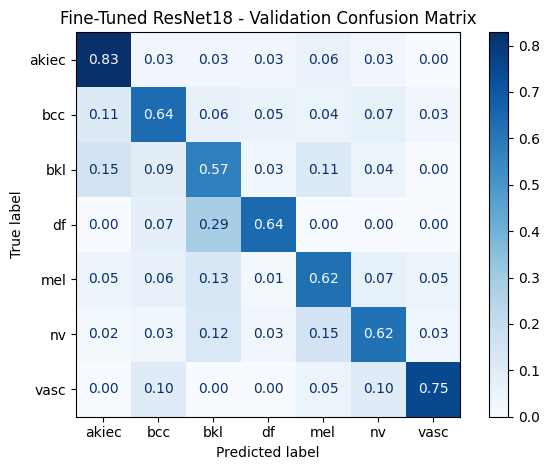

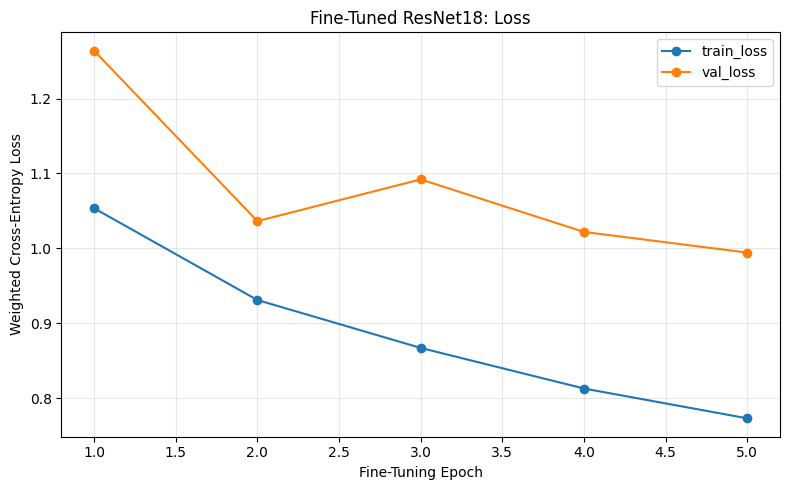

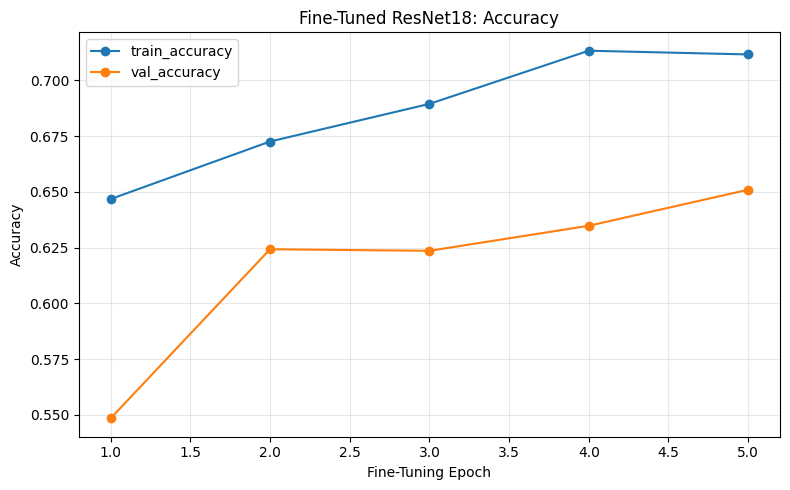

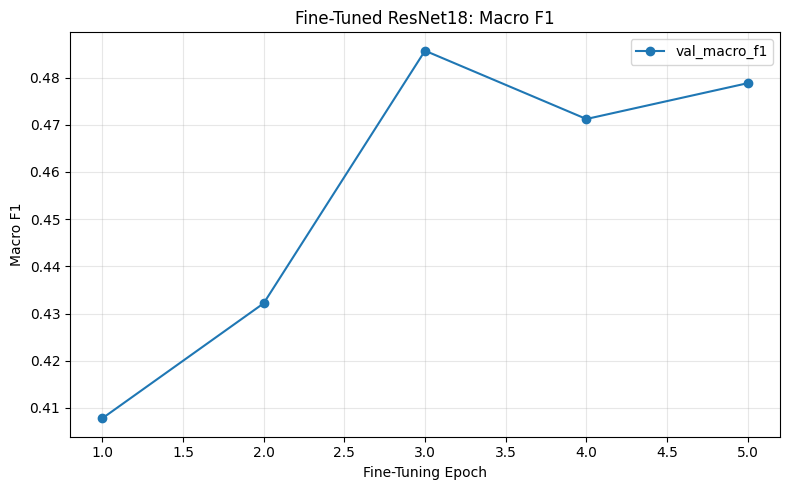

Fine-tuning evaluation saved to Google Drive.


In [ ]:

import os
import torch
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Restore best fine-tuned checkpoint (Epoch 3)
checkpoint = torch.load(
    os.path.join(
        resnet_save_folder,
        "best_resnet18_finetuned.pth"
    ),
    map_location=device,
    weights_only=True
)

resnet_model.load_state_dict(checkpoint["model_state_dict"])
resnet_model.eval()

# Evaluate validation data only
true_labels = []
pred_labels = []

with torch.no_grad():
    for images, labels in resnet_val_loader:
        images = images.to(device)
        outputs = resnet_model(images)

        pred_labels.extend(outputs.argmax(1).cpu().tolist())
        true_labels.extend(labels.tolist())

print("FINE-TUNED RESNET18 VALIDATION RESULTS")
print("--------------------------------------")
print("Accuracy:", round(
    accuracy_score(true_labels, pred_labels), 4
))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(true_labels, pred_labels), 4
))
print("Macro F1:", round(
    f1_score(
        true_labels, pred_labels,
        average="macro", zero_division=0
    ), 4
))

print("\nClassification Report:")
print(classification_report(
    true_labels,
    pred_labels,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    true_labels,
    pred_labels,
    labels=list(range(len(classes))),
    display_labels=classes,
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)

plt.title("Fine-Tuned ResNet18 - Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(
    os.path.join(
        resnet_save_folder,
        "finetuned_resnet18_confusion_matrix.png"
    ),
    dpi=300
)
plt.show()

# Fine-tuning curves
ft_history = pd.read_csv(
    os.path.join(
        resnet_save_folder,
        "resnet18_finetuning_history.csv"
    )
)

for columns, title, filename, ylabel in [
    (
        ["train_loss", "val_loss"],
        "Fine-Tuned ResNet18: Loss",
        "finetuned_resnet18_loss.png",
        "Weighted Cross-Entropy Loss"
    ),
    (
        ["train_accuracy", "val_accuracy"],
        "Fine-Tuned ResNet18: Accuracy",
        "finetuned_resnet18_accuracy.png",
        "Accuracy"
    ),
    (
        ["val_macro_f1"],
        "Fine-Tuned ResNet18: Macro F1",
        "finetuned_resnet18_macro_f1.png",
        "Macro F1"
    )
]:
    plt.figure(figsize=(8, 5))
    for column in columns:
        plt.plot(
            ft_history["epoch"],
            ft_history[column],
            marker="o",
            label=column
        )

    plt.title(title)
    plt.xlabel("Fine-Tuning Epoch")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(resnet_save_folder, filename),
        dpi=300
    )
    plt.show()

print("Fine-tuning evaluation saved to Google Drive.")


,Feature,Importance,Std
0,age,0.0594,0.0076
2,localization,0.0559,0.0071
1,sex,0.0028,0.0078


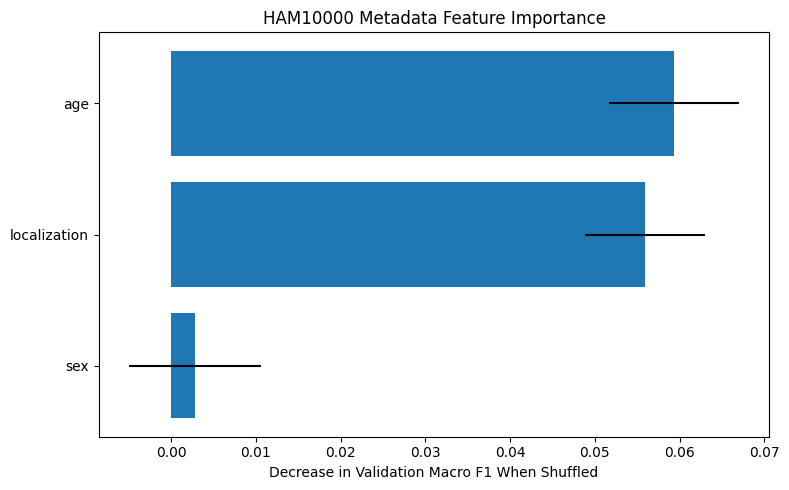

Feature importance results saved!


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.inspection import permutation_importance

# Restore metadata inputs from our saved split
features = ["age", "sex", "localization"]

train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]

X_train = train_df[features]
y_train = train_df["dx"]

X_val = val_df[features]
y_val = val_df["dx"]

# Create fresh preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer([
    (
        "age",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        ["age"]
    ),
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        ["sex", "localization"]
    )
])

# Use our tuned Random Forest
rf_feature_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        random_state=123,
        n_jobs=-1
    ))
])

# Fit using training data only
rf_feature_model.fit(X_train, y_train)

# Measure importance using validation Macro F1
importance = permutation_importance(
    rf_feature_model,
    X_val,
    y_val,
    scoring="f1_macro",
    n_repeats=10,
    random_state=123,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))

# Plot feature importance
plt.figure(figsize=(8, 5))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Std"]
)

plt.xlabel("Decrease in Validation Macro F1 When Shuffled")
plt.title("HAM10000 Metadata Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()

# Save graph and table
save_path = "/content/drive/MyDrive/DMML Project/Feature Analysis"
os.makedirs(save_path, exist_ok=True)

plt.savefig(
    os.path.join(save_path, "metadata_feature_importance.png"),
    dpi=300
)
plt.show()

importance_df.to_csv(
    os.path.join(save_path, "metadata_feature_importance.csv"),
    index=False
)

print("Feature importance results saved!")


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

feature_sets = {
    "All Features": ["age", "sex", "localization"],
    "Without Sex": ["age", "localization"]
}

feature_results = []

for name, selected_features in feature_sets.items():

    categorical = [
        f for f in selected_features if f != "age"
    ]

    preprocessing = ColumnTransformer([
        ("age", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), ["age"]),

        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical)
    ])

    model = Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            min_samples_leaf=10,
            class_weight="balanced_subsample",
            random_state=123,
            n_jobs=-1
        ))
    ])

    model.fit(
        train_df[selected_features],
        y_train
    )

    predictions = model.predict(
        val_df[selected_features]
    )

    feature_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        )
    })

feature_comparison = pd.DataFrame(feature_results)

display(feature_comparison.round(4))


,Model,Accuracy,Macro F1
0,All Features,0.4171,0.2281
1,Without Sex,0.3897,0.2147


In [ ]:

import os
import json

# Freeze our model choices before final testing
model_config = {
    "random_state": 123,
    "features": ["age", "sex", "localization"],
    "target": "dx",
    "selection_metric": "macro_f1",
    "selected_traditional_model": {
        "name": "KNeighborsClassifier",
        "n_neighbors": 11,
        "weights": "distance"
    },
    "selected_image_model": {
        "name": "ResNet18",
        "checkpoint": "best_resnet18_finetuned.pth",
        "selection_epoch": 3
    },
    "test_split": "test"
}

config_folder = (
    "/content/drive/MyDrive/DMML Project/Final Evaluation"
)

os.makedirs(config_folder, exist_ok=True)

with open(
    os.path.join(config_folder, "model_config.json"),
    "w"
) as f:
    json.dump(model_config, f, indent=4)

print("Model configurations saved!")
print("Selected traditional model: kNN (k=11)")
print("Selected image model: Fine-tuned ResNet18")


Model configurations saved!
Selected traditional model: kNN (k=11)
Selected image model: Fine-tuned ResNet18


Test images: 1422
Lesion overlap: 0

 kNN (Metadata)
-------------------------
Accuracy: 0.6238
Balanced accuracy: 0.2126
Macro F1: 0.2057
              precision    recall  f1-score   support

       akiec       0.15      0.23      0.18        56
         bcc       0.13      0.12      0.12        52
         bkl       0.20      0.20      0.20       143
          df       0.00      0.00      0.00        15
         mel       0.14      0.10      0.12       156
          nv       0.81      0.84      0.83       978
        vasc       0.00      0.00      0.00        22

    accuracy                           0.62      1422
   macro avg       0.20      0.21      0.21      1422
weighted avg       0.60      0.62      0.61      1422


 Fine-tuned ResNet18 (Images)
-------------------------
Accuracy: 0.6181
Balanced accuracy: 0.6085
Macro F1: 0.465
              precision    recall  f1-score   support

       akiec       0.31      0.48      0.38        56
         bcc       0.32      0.69      

,Model,Accuracy,Balanced Accuracy,Macro F1
0,kNN (Metadata),0.6238,0.2126,0.2057
1,Fine-tuned ResNet18 (Images),0.6181,0.6085,0.4650


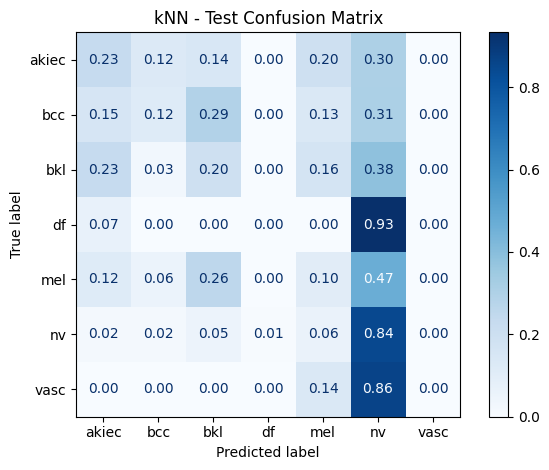

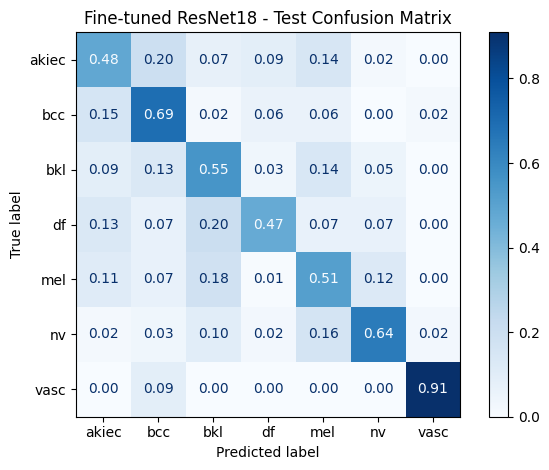


Final test results saved to Google Drive!


In [ ]:

import os
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Use our original, untouched test split
test_df = df[df["split"] == "test"].copy()
development_df = df[df["split"].isin(["train", "val"])].copy()

assert len(test_df) == 1422
assert len(set(test_df["lesion_id"]) &
           set(development_df["lesion_id"])) == 0

print("Test images:", len(test_df))
print("Lesion overlap: 0")

# ---------------------------------
# PART A: kNN METADATA MODEL
# ---------------------------------

features = ["age", "sex", "localization"]

preprocessing = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), ["age"]),

    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     ["sex", "localization"])
])

final_knn = Pipeline([
    ("preprocessing", preprocessing),
    ("classifier", KNeighborsClassifier(
        n_neighbors=11,
        weights="distance"
    ))
])

# Refit using training + validation
final_knn.fit(
    development_df[features],
    development_df["dx"]
)

knn_test_preds = final_knn.predict(test_df[features])

# ---------------------------------
# PART B: RESNET18 IMAGE MODEL
# ---------------------------------

# No augmentation on test images
resnet_test_dataset = HAM10000Dataset(
    test_df,
    image_dict,
    resnet_val_transform
)

resnet_test_loader = DataLoader(
    resnet_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# Restore the best fine-tuned checkpoint
checkpoint_path = os.path.join(
    resnet_save_folder,
    "best_resnet18_finetuned.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

resnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)
resnet_model.eval()

resnet_test_preds = []
resnet_test_true = []

with torch.no_grad():
    for images, labels in resnet_test_loader:
        images = images.to(device)
        outputs = resnet_model(images)

        resnet_test_preds.extend(
            outputs.argmax(dim=1).cpu().tolist()
        )
        resnet_test_true.extend(labels.tolist())

# Convert numeric CNN predictions to class names
resnet_predictions = [
    classes[i] for i in resnet_test_preds
]

# Check label ordering
assert resnet_test_true == [
    class_to_idx[label] for label in test_df["dx"]
]

# ---------------------------------
# PART C: COMPARE FINAL RESULTS
# ---------------------------------

y_test = test_df["dx"]

def evaluate(name, predictions):
    print("\n", name)
    print("-------------------------")

    accuracy = accuracy_score(y_test, predictions)
    balanced = balanced_accuracy_score(y_test, predictions)
    macro_f1 = f1_score(
        y_test, predictions,
        average="macro", zero_division=0
    )

    print("Accuracy:", round(accuracy, 4))
    print("Balanced accuracy:", round(balanced, 4))
    print("Macro F1:", round(macro_f1, 4))

    print(classification_report(
        y_test, predictions,
        labels=classes,
        zero_division=0
    ))

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced,
        "Macro F1": macro_f1
    }

knn_result = evaluate("kNN (Metadata)", knn_test_preds)
resnet_result = evaluate(
    "Fine-tuned ResNet18 (Images)",
    resnet_predictions
)

final_results = pd.DataFrame([
    knn_result,
    resnet_result
])

display(final_results.round(4))

# ---------------------------------
# PART D: SAVE RESULTS AND GRAPHS
# ---------------------------------

output_folder = (
    "/content/drive/MyDrive/DMML Project/Final Evaluation"
)
os.makedirs(output_folder, exist_ok=True)

final_results.to_csv(
    os.path.join(output_folder, "final_test_results.csv"),
    index=False
)

for name, predictions, filename in [
    ("kNN", knn_test_preds, "knn_test_confusion.png"),
    ("Fine-tuned ResNet18", resnet_predictions,
     "resnet18_test_confusion.png")
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=classes,
        normalize="true",
        cmap="Blues",
        values_format=".2f"
    )

    plt.title(f"{name} - Test Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        os.path.join(output_folder, filename),
        dpi=300
    )
    plt.show()

print("\nFinal test results saved to Google Drive!")
